In [1]:
%%html
<style>
div.optional {
    display: block;
    background-color: #d7e2ff;
    border-color: #d7e2ff;
    border-left: 5px solid #d7e2ff;
    padding: 0.5em;
}
div.advanced {
    display: block;
    background-color: #fff4d7;
    border-color: #fff4d7;
    border-left: 5px solid #fff4d7;
    padding: 0.5em;
}
</style>

In [2]:
%matplotlib inline
%precision 6
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sl
from pprint import pprint

# if you get a ffmpeg error when creating movies try `conda install -c conda-forge ffmpeg` and restart Anaconda

# Computational Mathematics  <a class="tocSkip">

## Linear Algebra 2  <a class="tocSkip">
### (more linear algebra and some of its applications, especially the link to solving systems of ODEs)  <a class="tocSkip">
    
### Some supplementary material  <a class="tocSkip">

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Geometric-interpretation-of-linear-transformations;-change-of-bases;-eigenvectors---a-more-in-depth-investigation" data-toc-modified-id="Geometric-interpretation-of-linear-transformations;-change-of-bases;-eigenvectors---a-more-in-depth-investigation-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Geometric interpretation of linear transformations; change of bases; eigenvectors - a more in-depth investigation</a></span><ul class="toc-item"><li><span><a href="#Writing-a-fixed-location-in-terms-of-a-new-basis" data-toc-modified-id="Writing-a-fixed-location-in-terms-of-a-new-basis-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>Writing a fixed location in terms of a new basis</a></span></li><li><span><a href="#Writing-a-transformation-in-terms-of-a-new-basis-[*]" data-toc-modified-id="Writing-a-transformation-in-terms-of-a-new-basis-[*]-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>Writing a transformation in terms of a new basis [*]</a></span><ul class="toc-item"><li><span><a href="#Some-fairly-complicated-examples-[**]" data-toc-modified-id="Some-fairly-complicated-examples-[**]-1.2.1"><span class="toc-item-num">1.2.1&nbsp;&nbsp;</span>Some fairly complicated examples [**]</a></span></li></ul></li><li><span><a href="#Transformation-of-a-unit-sphere" data-toc-modified-id="Transformation-of-a-unit-sphere-1.3"><span class="toc-item-num">1.3&nbsp;&nbsp;</span>Transformation of a unit sphere</a></span></li><li><span><a href="#A-symmetric-positive-definite-case" data-toc-modified-id="A-symmetric-positive-definite-case-1.4"><span class="toc-item-num">1.4&nbsp;&nbsp;</span>A symmetric positive definite case</a></span></li></ul></li><li><span><a href="#Some-applications-of-eigen-values/vectors" data-toc-modified-id="Some-applications-of-eigen-values/vectors-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Some applications of eigen-values/vectors</a></span><ul class="toc-item"><li><span><a href="#Linear-systems" data-toc-modified-id="Linear-systems-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Linear systems</a></span><ul class="toc-item"><li><span><a href="#Re-interpretation-in-terms-of-eigenvalues-and-eigenvectors" data-toc-modified-id="Re-interpretation-in-terms-of-eigenvalues-and-eigenvectors-2.1.1"><span class="toc-item-num">2.1.1&nbsp;&nbsp;</span>Re-interpretation in terms of eigenvalues and eigenvectors</a></span></li></ul></li><li><span><a href="#Powers-of-matrices-[*---but-note-we-are-going-to-use-this-result-in-the-next-section]" data-toc-modified-id="Powers-of-matrices-[*---but-note-we-are-going-to-use-this-result-in-the-next-section]-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>Powers of matrices [* - but note we are going to use this result in the next section]</a></span><ul class="toc-item"><li><span><a href="#Fibonacci-numbers" data-toc-modified-id="Fibonacci-numbers-2.2.1"><span class="toc-item-num">2.2.1&nbsp;&nbsp;</span>Fibonacci numbers</a></span></li></ul></li><li><span><a href="#Using-linear-algebra-to-solve-systems-of-ODEs" data-toc-modified-id="Using-linear-algebra-to-solve-systems-of-ODEs-2.3"><span class="toc-item-num">2.3&nbsp;&nbsp;</span>Using linear algebra to solve systems of ODEs</a></span><ul class="toc-item"><li><span><a href="#The-idea/theory" data-toc-modified-id="The-idea/theory-2.3.1"><span class="toc-item-num">2.3.1&nbsp;&nbsp;</span>The idea/theory</a></span></li><li><span><a href="#An-example" data-toc-modified-id="An-example-2.3.2"><span class="toc-item-num">2.3.2&nbsp;&nbsp;</span>An example</a></span></li><li><span><a href="#Making-use-of-matrix-diagonalisation" data-toc-modified-id="Making-use-of-matrix-diagonalisation-2.3.3"><span class="toc-item-num">2.3.3&nbsp;&nbsp;</span>Making use of matrix diagonalisation</a></span></li></ul></li></ul></li><li><span><a href="#Analysing-and-solving-a-second-order-ODE-(the-Mass-Spring-Damper-problem)" data-toc-modified-id="Analysing-and-solving-a-second-order-ODE-(the-Mass-Spring-Damper-problem)-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Analysing and solving a second-order ODE (the Mass-Spring-Damper problem)</a></span><ul class="toc-item"><li><span><a href="#Writing-as-a-linear-system" data-toc-modified-id="Writing-as-a-linear-system-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Writing as a linear system</a></span></li><li><span><a href="#Discretisation-with-forward-Euler" data-toc-modified-id="Discretisation-with-forward-Euler-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Discretisation with forward Euler</a></span></li><li><span><a href="#Exercises" data-toc-modified-id="Exercises-3.3"><span class="toc-item-num">3.3&nbsp;&nbsp;</span>Exercises</a></span></li><li><span><a href="#Analysing-an-ODE-system:-diagonalisation" data-toc-modified-id="Analysing-an-ODE-system:-diagonalisation-3.4"><span class="toc-item-num">3.4&nbsp;&nbsp;</span>Analysing an ODE system: diagonalisation</a></span></li><li><span><a href="#Eigenvalue-analysis" data-toc-modified-id="Eigenvalue-analysis-3.5"><span class="toc-item-num">3.5&nbsp;&nbsp;</span>Eigenvalue analysis</a></span></li><li><span><a href="#Stability-of-the-continuous-problem" data-toc-modified-id="Stability-of-the-continuous-problem-3.6"><span class="toc-item-num">3.6&nbsp;&nbsp;</span>Stability of the <em>continuous problem</em></a></span></li><li><span><a href="#The-exact-solution" data-toc-modified-id="The-exact-solution-3.7"><span class="toc-item-num">3.7&nbsp;&nbsp;</span>The exact solution</a></span></li><li><span><a href="#Comparing-the-analytical-solution-against-a-numerical-solver" data-toc-modified-id="Comparing-the-analytical-solution-against-a-numerical-solver-3.8"><span class="toc-item-num">3.8&nbsp;&nbsp;</span>Comparing the analytical solution against a numerical solver</a></span><ul class="toc-item"><li><span><a href="#An-aside-on-generating-animations" data-toc-modified-id="An-aside-on-generating-animations-3.8.1"><span class="toc-item-num">3.8.1&nbsp;&nbsp;</span>An aside on generating animations</a></span></li></ul></li></ul></li><li><span><a href="#A-coupled-mass-spring-damper-system-and-a-fancier-ODE-solver" data-toc-modified-id="A-coupled-mass-spring-damper-system-and-a-fancier-ODE-solver-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>A coupled mass spring damper system and a fancier ODE solver</a></span></li></ul></div>

# Geometric interpretation of linear transformations; change of bases; eigenvectors - a more in-depth investigation

Recall from the end of the last lecture where we established that:


1. if we are considering certain transformations of point(s) or space,  e.g. rotations, scaling, shear, we can describe this via multiplication by a certain matrix - we start from something physical/geometrical and look to interpret/use this in terms of a matrix.


2. on the flip-side, if we instead start with a matrix we can consider it in terms of its geometrical transformation properties.


We can extend this to consider how we might represent points in a different coordinate system (i.e. in terms of different basis vectors), and how we would describe a transformation in terms of a different coordinate system. 

Why might we want to do this? In both cases considering a different coordinate system may make things easier for us.

Let's consider some examples.

## Writing a fixed location in terms of a new basis

What we did previously was consider the transformation

$$\boldsymbol{p}\longrightarrow \boldsymbol{p}' = A\boldsymbol{p}$$

or

$$p_1 \boldsymbol{i} +  p_2\boldsymbol{j} \longrightarrow  p_1 (A\boldsymbol{i}) + p_2 (A\boldsymbol{j})$$

In the original coordinate system we moved the distance $p_1$ in direction $\boldsymbol{i}$ and $p_2$ in direction $\boldsymbol{j}$ (it doesn't matter in which order of course, we end up at the same position).

Now as we could interpret this transformation in terms of the coefficients being held constant, with only the basis vectors transformed by the matrix multiplication, it turned out that in the new coordinates (i.e. in terms of the new basis vectors) we moved the same multiples but of new basis vectors: $p_1$ multiplied by  $A \boldsymbol{i}$ and $p_2$ multiplied $A\boldsymbol{j}$. 

I used the word 'multiples' here rather than distance to emphasise that even if the original basis vectors were normalised, the new ones might not be - as $\boldsymbol{i}$ has unit length we can just talk about direction $\boldsymbol{i}$, as  $A \boldsymbol{i}$ may not have unit length we should be careful about talking about direction  $A \boldsymbol{i}$!

A consequence of this transformation is of course that the location of the point $\boldsymbol{p}$ changes along with the coordinates.

But for some applications this may not be what we wanted.

Often our point will be fixed in space and we will simply want to describe that same location using a different coordinate system. In this case we will clearly need to update the coefficients as well. 

We will want to find new coefficients or coordinates $p_1'$ and $p_2'$ such that the location of the point is unchanged. Mathematically this can be written as

$$p_1 \boldsymbol{i} +  p_2\boldsymbol{j} = p_1' (A\boldsymbol{i}) + p_2' (A\boldsymbol{j})$$

If I write this in terms of matrices, with the columns of the matrix representing the basis vectors, then this equivalence can be written as

$$I  \boldsymbol{p} = (AI) \boldsymbol{p}'$$

(where I have explicitly included the identity matrix on the LHS here since we used a simple form for the original basis vectors - the columns of the identity matrix are our $\boldsymbol{i}$ and $\boldsymbol{j}$ basis vectors.  This could be generalised to any starting basis vectors/matrix).

Remember I want to find $\boldsymbol{p}'$ such that the above equivalence is true. 

Thinking about things in this matrix form tells us how we can do this - simply multiply both sides by the inverse of $(AI)$ (I leave this as $AI$ here rather than rewriting as $A$ just to emphasise that the $I$ is encoding the original basis; it can't be ignored if we started from something other than the $\boldsymbol{i}, \;\boldsymbol{j}$ basis):

$$ \boldsymbol{p}' = (AI)^{-1}  I  \boldsymbol{p} = I^{-1} A^{-1} I \boldsymbol{p}$$

this is of course for our case simply 

$$ \boldsymbol{p}' = A^{-1} \boldsymbol{p}$$

(but we'd need to include the analogue of the $I$ matrix if we had a more complicated starting basis)

Let's confirm this result visually

(-0.300000, 3.000000)

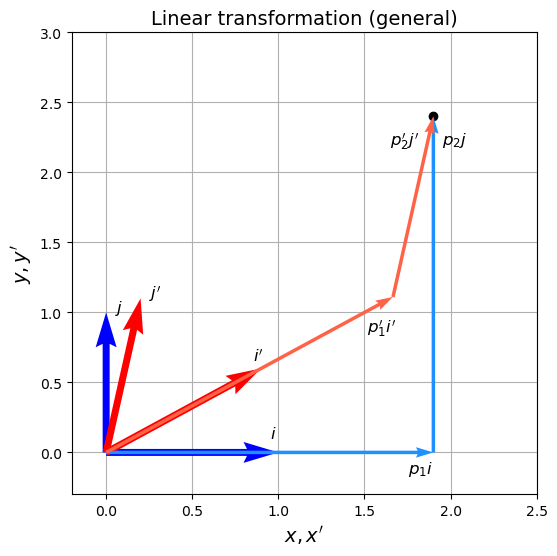

In [3]:
fig = plt.figure(figsize=(6, 6))

ax1 = fig.add_subplot(111)

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation (general)', fontsize=14)
ax1.grid(True)

# original basis vectors
i = np.array([1,0])
j = np.array([0,1])

# plot the vectors
ax1.quiver(i[0], i[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(j[0], j[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)

# add some text
ax1.text(i[0]-0.05, i[1]+0.1, "$i$", fontsize=12)
ax1.text(j[0]+0.05,j[1], "$j$", fontsize=12)


# transformation matrix
A = np.array([[0.9,0.2],[0.6,1.1]])


#  **** transformed basis vectors ****
i_ = A@i
j_ = A@j


# plot the transformed vectors
ax1.quiver(i_[0], i_[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10, width=0.015)
ax1.quiver(j_[0], j_[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10, width=0.015)

# add some text
ax1.text(i_[0]-0.05, i_[1]+0.05, "$i'$", fontsize=12)
ax1.text(j_[0]+0.05,j_[1], "$j'$", fontsize=12)

# add a point
p = 1.9*i + 2.4*j

# plot it
ax1.plot(p[0],p[1],'ko')

# plot components - the lighter blue vectors in the i and j directions
ax1.quiver(p[0]*i[0], p[0]*i[1], angles='xy', scale_units='xy', scale=1, color='dodgerblue', zorder=20)
ax1.quiver(p[0]*i[0], p[0]*i[1], p[1]*j[0], p[1]*j[1], angles='xy', scale_units='xy', scale=1, 
           color='dodgerblue', zorder=20)

# add some text
ax1.text(p[0]*i[0]-0.15, p[0]*i[1]-0.15, "$p_1 i$", fontsize=12)
ax1.text(p[0]*i[0]+p[1]*j[0]+0.05, p[0]*i[1]+p[1]*j[1]-0.2, "$p_2 j$", fontsize=12)


# **** define transformed coefficients by multiplying by A^{-1}: ****
p_ = sl.inv(A)@p


# plot components in the new coordinates (i_ and j_) in light red
ax1.quiver(p_[0]*i_[0], p_[0]*i_[1], angles='xy', scale_units='xy', scale=1, color='tomato', zorder=20)
ax1.quiver(p_[0]*i_[0], p_[0]*i_[1], p_[1]*j_[0], p_[1]*j_[1], angles='xy', scale_units='xy', scale=1, 
           color='tomato', zorder=20)

# add some text
ax1.text(p_[0]*i_[0]-0.15, p_[0]*i_[1]-0.25, "$p_1' i'$", fontsize=12)
ax1.text(p_[0]*i_[0]+p_[1]*j_[0]-0.25, p_[0]*i_[1]+p_[1]*j_[1]-0.2, "$p_2' j'$", fontsize=12)

ax1.set_xlim(-0.2,2.5)
ax1.set_ylim(-0.3,3)

The primed $\boldsymbol{i}$ and $\boldsymbol{j}$ vectors are our transformed basis, here given by the columns of the arbitrarily chosen transformation matrix $A$. We clearly see if we move the appropriate multiples of these vectors, with the multiples given by $\boldsymbol{p}'$, then we do indeed end up at our original starting $ \boldsymbol{p}$ location.


So we know how to write an unchanged (i.e. un-transformed) position in terms of different basis vectors.

<div class="optional">

## Writing a transformation in terms of a new basis [*]

Let's extend that to now think about how we would write a transformation in terms of a different basis.

For example, assume that we transform a point in the original basis using a transformation described by matrix multiplication (what we did at the end of the previous lecture - e.g. a shear or a rotation). 

How would we describe that same transformation in terms of a different basis?

Consider this example:  suppose we consider the transformation of a point where we reflect the position about the $y$ axis ($x\rightarrow -x$), and we stretch by a factor of 2 in the $y$ direction ($y\rightarrow 2y$). In terms of the simple basis vectors $\boldsymbol{i}$ and $\boldsymbol{j}$ aligned with the $x$ and $y$ directions, this can obviously be represented by the matrix

$$A=
\begin{pmatrix}
-1 & 0 \\
0 & 2
\end{pmatrix}
$$

Now let's pretend that we were using different basis vectors to describe our original location. Let's assume we wanted to update that location in the same manner as just described. 

In terms of the second set of basis vectors we wouldn't simply swap the sign of the first value and multiply the second value by 2, this would take us to the wrong location. So we need a different transformation matrix to above. What is this?

Well the answer is to compose transformations, equivalently to multiply matrices.

Note that the reason we may want to do this is exactly because in terms of a particular basis a transformation may be especially easy to write down, or to interpret.

In the example in the following cell the matrix $A$ defined just above transforms our point using the original basis:

if $\boldsymbol{p}$ is our original point in terms of the original simple basis vectors, then
$\boldsymbol{q}=A\boldsymbol{p}$ is our transformed point in terms of the same original vectors.
    
</div>

<div class="optional">

Now consider a new set of basis vectors obtained by pre-multiplication by a matrix, e.g.

$$A_b = 
\begin{pmatrix}
    0.9 & 0.2\\
    0.6 & 1.1
\end{pmatrix}
$$

Based on what we saw above, $A_b^{-1}\boldsymbol{p}$ gives the coordinates of the *original point* in terms of the new basis.

So starting from a point $\boldsymbol{p}$, 

$A\boldsymbol{p}$ transforms it in the original basis, 

and $A_b^{-1}A\boldsymbol{p}$ is then the *transformed point written in terms of the new basis vectors*.

Admittedly this is getting a bit complicated, let's plot all of this to confirm it's correct and maybe understand a bit better what is going on

Let 

- $\boldsymbol{p}\,$ denote the coordinates of the original point in terms of the first set of basis vectors


- $\boldsymbol{q}\,$ denote the coordinates of the transformed point in terms of the first set of basis vectors


- $\boldsymbol{p'}\,$ denote the coordinates of the original point in terms of the second set of basis vectors


- $\boldsymbol{q'}\,$ denote the coordinates of the transformed point in terms of the second set of basis vectors
    
</div>

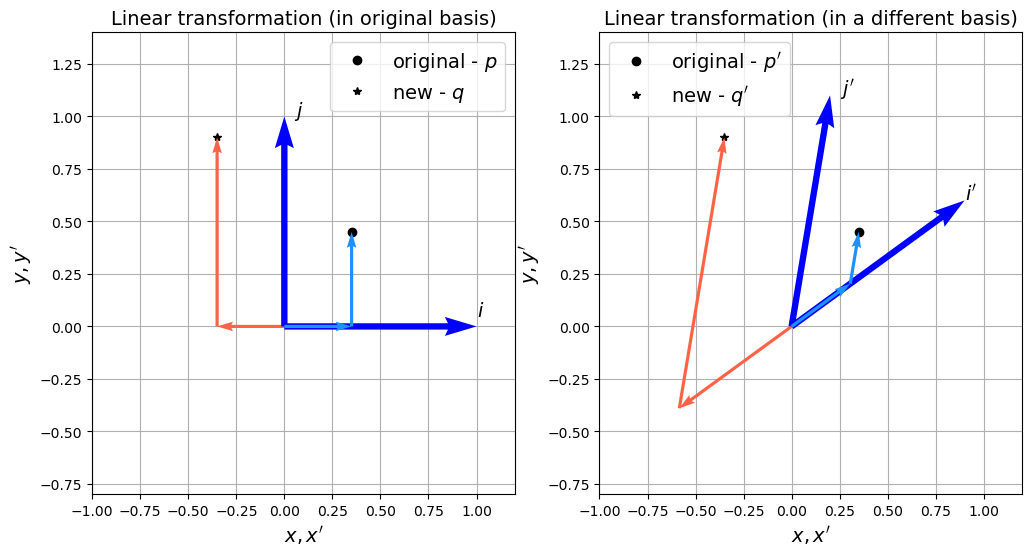

In [4]:
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(121)

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation (in original basis)', fontsize=14)
ax1.grid(True)

# original basis vectors
i = np.array([1,0])
j = np.array([0,1])

# plot the vectors
ax1.quiver(i[0], i[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(j[0], j[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)

# add some text
ax1.text(i[0], i[1]+0.05, "$i$", fontsize=14)
ax1.text(j[0]+0.05,j[1], "$j$", fontsize=14)

# transformation matrix
A = np.array([[-1,0],[0,2]])

# add a point
p = 0.35*i + 0.45*j

# plot it
ax1.plot(p[0],p[1],'ko', label='original - $p$')

# plot components
ax1.quiver(p[0]*i[0], p[0]*i[1], angles='xy', scale_units='xy', scale=1, color='dodgerblue', zorder=20)
ax1.quiver(p[0]*i[0], p[0]*i[1], p[1]*j[0], p[1]*j[1], angles='xy', scale_units='xy', 
           scale=1, color='dodgerblue', zorder=20)

# transform the point
q = A@p

# plot it
ax1.plot(q[0],q[1],'k*', label='new - $q$')

# plot components
ax1.quiver(q[0]*i[0], q[0]*i[1], angles='xy', scale_units='xy', scale=1, color='tomato', zorder=5)
ax1.quiver(q[0]*i[0], q[0]*i[1], q[1]*j[0], q[1]*j[1], angles='xy', scale_units='xy', scale=1, color='tomato', zorder=5)

ax1.set_xlim(-1.0,1.2)
ax1.set_ylim(-0.8,1.4)

ax1.legend(loc='best', fontsize=14)
##################################
ax1 = fig.add_subplot(122)

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation (in a different basis)', fontsize=14)
ax1.grid(True)

# original basis vectors
i = np.array([1,0])
j = np.array([0,1])

# plot original point
ax1.plot(p[0],p[1],'ko', label="original - $p'$")

# transformation matrix to obtain a new basis
Ab = np.array([[0.9,0.2],[0.6,1.1]])

# transformed basis vectors
i_ = Ab@i
j_ = Ab@j

# plot the vectors
ax1.quiver(i_[0], i_[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(j_[0], j_[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)

# add some text
ax1.text(i_[0], i_[1], "$i'$", fontsize=14)
ax1.text(j_[0]+0.05,j_[1], "$j'$", fontsize=14)

# coordinates of original point in new basis
p_ = sl.inv(Ab)@p

# plot components to show that these give the same location in terms of i_ and j_
ax1.quiver(p_[0]*i_[0], p_[0]*i_[1], angles='xy', scale_units='xy', scale=1, color='dodgerblue', zorder=20)
ax1.quiver(p_[0]*i_[0], p_[0]*i_[1], p_[1]*j_[0], p_[1]*j_[1], angles='xy', scale_units='xy', 
           scale=1, color='dodgerblue', zorder=20)


# coordinates of point in terms of the transformation given by A, but in original basis
q = A@p

# plot it
ax1.plot(q[0],q[1],'k*', label="new - $q'$")

# now let's check that we can get to the same location using our second basis - how do I write q in terms i_, j_
q_ = sl.inv(Ab)@q

# plot components
ax1.quiver(q_[0]*i_[0], q_[0]*i_[1], angles='xy', scale_units='xy', scale=1, color='tomato', zorder=5)
ax1.quiver(q_[0]*i_[0], q_[0]*i_[1], q_[1]*j_[0], q_[1]*j_[1], angles='xy', scale_units='xy', 
           scale=1, color='tomato', zorder=5)

ax1.set_xlim(-1.0,1.2)
ax1.set_ylim(-0.8,1.4)

ax1.legend(loc='best', fontsize=14)

<div class="optional">

If we started with a point $\boldsymbol{p}'$ in the second coordinate system, but we could describe our transformation more easily in the first coordinate system (as in the example above), then we would do the following:


1. Starting from a point in the second coordinate system, pre-multiply by $A_b$ to map to coordinates in the first ($\boldsymbol{p}=A_b\boldsymbol{p}'$)


2. Now pre-multiply by $A$ to perform the transformation of the point written in terms of the first basis
($\boldsymbol{q}=A\boldsymbol{p}$)


3. Finally  pre-multiply by $A_b^{-1}$ to map these new coordinates back into the second coordinate system
($\boldsymbol{q}'=A_b^{-1}\boldsymbol{q}$)


Combining:

$$ \boldsymbol{q}' = A_b^{-1} \, A \, A_b\,  \boldsymbol{p'} $$

this combined matrix on the left $(A_b^{-1} \, A \, A_b)$ is what we would need to multiply through by to start with a  $\boldsymbol{p'}$ given by the black dot on the RHS image above, and jump straight to the black star in the image on the right, for example.


If our transformation was more convenient to write in terms of the second set of basis vectors then we would just go in the opposite direction - starting from a point  $\boldsymbol{p}$ in the original basis,  

$$ \boldsymbol{q} = A_b \, A \, A_b^{-1}\,  \boldsymbol{p}$$ 

would be the transformed point.

Note that the $A_b$ and $A_b^{-1}$ are interchangeable depending on which direction we interpret the transformation $A_b$ to be in.

We'll return to something analogous when we introduce **matrix diagonalisation** a little later!
    
</div>

<div class="advanced">

### Some fairly complicated examples [\**]

Let's now consider a scenario where we want to reflect a point across a line oriented 60 degrees from the $x$ axis.

Suppose we have a $\boldsymbol{p}$ written in terms of a first coordinate system assumed to be $\boldsymbol{i}$, $\boldsymbol{j}$.

An easy way to achieve this transformation is to first rotate our coordinate system so that this line is oriented with the $y$ axis, we can do this by rotating *clockwise* by 30 degrees ($90-60$): we pre-multiply our vector by the inverse of

$$A_b = 
\begin{pmatrix}
\cos(\theta) & -\sin(\theta)\\
\sin(\theta) & \cos(\theta)
\end{pmatrix},\qquad \text{with} \quad \theta = -30\frac{\pi}{180} \quad\text{[Remembering that positive angle corresponds to an anti-clockwise rotation]}
$$

We then reflect about the $y$ axis (i.e. swap the sign of the $x$ component): we can do this through pre-multiplication by

$$A = 
\begin{pmatrix}
-1 & 0\\
0 & 1
\end{pmatrix}
$$

and finally we transform back to the original basis: we pre-multiply by $A_b$.

The new location can therefore be written as

$$\boldsymbol{q} = 
\begin{pmatrix}
\cos(\theta) & -\sin(\theta)\\
\sin(\theta) & \cos(\theta)
\end{pmatrix}
\begin{pmatrix}
-1 & 0\\
0 & 1
\end{pmatrix}
\begin{pmatrix}
\cos(\theta) & -\sin(\theta)\\
\sin(\theta) & \cos(\theta)
\end{pmatrix}^{-1}
\boldsymbol{p}
$$  

Let's plot this new point to check our above reasoning is correct.
    
</div>

(-0.200000, 1.200000)

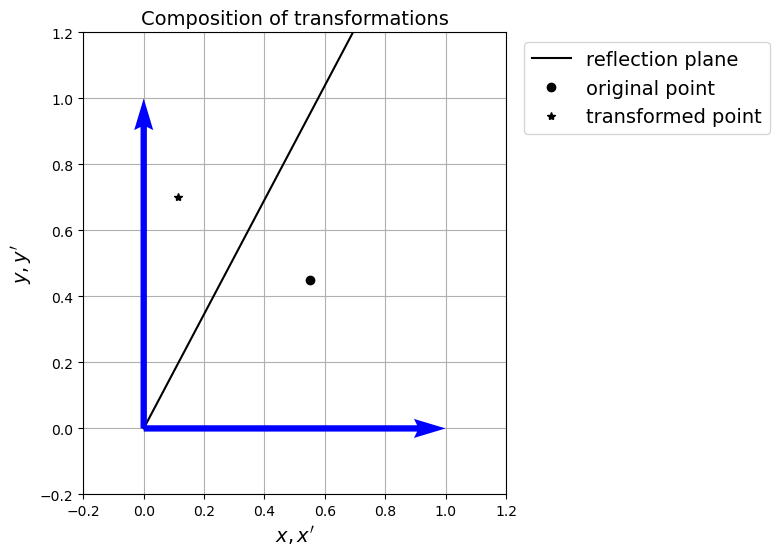

In [5]:
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(121)

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Composition of transformations', fontsize=14)
ax1.grid(True)

# original basis vectors
i = np.array([1,0])
j = np.array([0,1])

# plot the vectors
ax1.quiver(i[0], i[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(j[0], j[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)

# transform matrix for coordinates
theta = -30 *np.pi/180 
Ab = np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])

# plot a line to indicate what we are reflecting the point across
ax1.plot([0,3*np.cos(60*np.pi/180)],[0,3*np.sin(60*np.pi/180)],'k', label='reflection plane')

# transformation matrix
A = np.array([[-1, 0],[0, 1]])

# add a point
p = 0.55*i + 0.45*j

# plot it
ax1.plot(p[0], p[1], 'ko', label='original point')

# update the point and plot it in terms of the original basis vectors
q = Ab@A@sl.inv(Ab) @ p

# plot it
ax1.plot(q[0], q[1], 'k*', label='transformed point')

ax1.legend(fontsize=14, bbox_to_anchor=(1.02,1), loc="upper left")

ax1.set_xlim(-.2,1.2)
ax1.set_ylim(-.2,1.2)

<div class="advanced">

Success!

Let's print out that actual transformation matrix that takes us from the circular dot to the star in terms of the original basis vectors. The point here is that we have something that we wouldn't have been able to write down easily, but it's formed from the product of three matrices that we could easily write down.
    
</div>

In [6]:
print(Ab@A@sl.inv(Ab))

[[-0.5       0.866025]
 [ 0.866025  0.5     ]]


<div class="advanced">
    
Now suppose we wanted to *additionally* stretch the point along the direction of the line of reflection following a reflection, this is easy to do by combining (through matrix multiplication) simple transformations performed in the new basis.
    
</div>

[[-0.325     1.169134]
 [ 1.169134  1.025   ]]


(-0.200000, 1.200000)

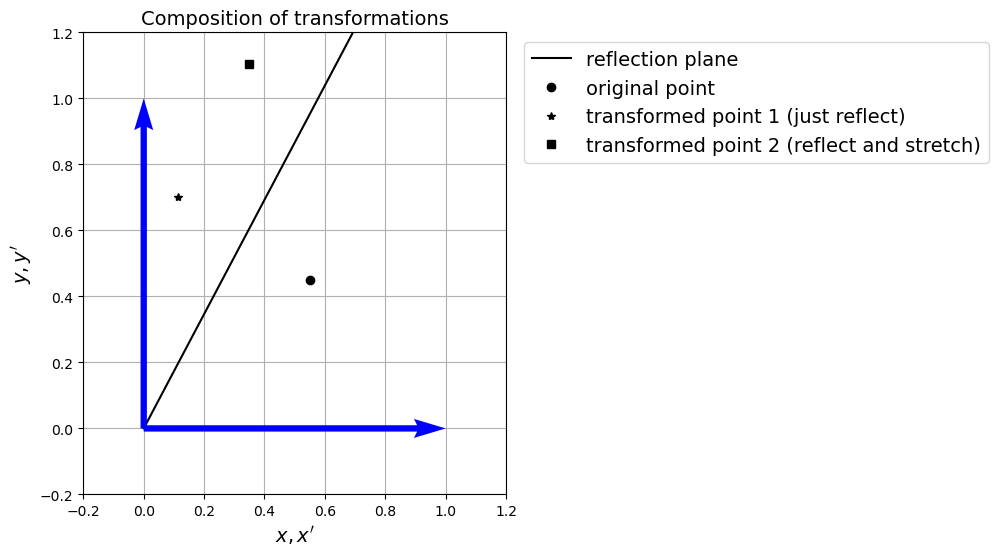

In [7]:
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(121)

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Composition of transformations', fontsize=14)
ax1.grid(True)

# original basis vectors
i = np.array([1,0])
j = np.array([0,1])

# plot the vectors
ax1.quiver(i[0], i[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(j[0], j[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)

# transform matrix for coordinates
theta = -30 *np.pi/180 
Ab = np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])

# plot a line to indicate what we are reflecting the point across
ax1.plot([0,3*np.cos(60*np.pi/180)],[0,3*np.sin(60*np.pi/180)],'k', label='reflection plane')

# transformation matrix 1 - this reflects the first component
A1 = np.array([[-1,0],[0,1]])


# additional linear transformation matrix - this scales the second component
A2 = np.array([[1, 0],[0, 1.7]])


# add a point
p = 0.55*i + 0.45*j

# plot it
ax1.plot(p[0],p[1],'ko', label='original point')

# update the point and plot it in terms of the original basis vectors
# this is just the reflection
q = Ab@A1@sl.inv(Ab) @p

# plot it
ax1.plot(q[0],q[1],'k*', label='transformed point 1 (just reflect)')

# this is the reflection followed by a stretch (by 1.7) along the direction given by the reflection plane
q = Ab@A2@A1@sl.inv(Ab) @p
print(Ab@A2@A1@sl.inv(Ab))
# plot it
ax1.plot(q[0],q[1],'ks', label='transformed point 2 (reflect and stretch)')

ax1.legend(fontsize=14, bbox_to_anchor=(1.02,1), loc="upper left")

ax1.set_xlim(-.2,1.2)
ax1.set_ylim(-.2,1.2)

<div class="advanced">
    
In the above the additional movement was via a *scaling* (by a factor 1.7) of *one* of the transformed coordinates. 
   
</div>

## Transformation of a unit sphere

We can also consider how all vectors (points) of a fixed unit magnitude transform by considering how a unit circle transforms under multiplication by an arbitrary matrix $A$.

Imagine the circle made up of a collection of points, each representing the vector from the origin. If we transform each of these points and maintain their ordering (i.e. maintain the lines joining them which approximate a continuous circle), what shape do we arrive at? 

This is an extension of the transformed square examples from last lecture of course.

In 3D we can of course think about a unit sphere, and so on to even higher dimensions.

These concepts of thinking about matrices in terms of transformations can also be applied to non-square matrices.

(-2.441768, 2.442281, -3.325370, 3.324818)

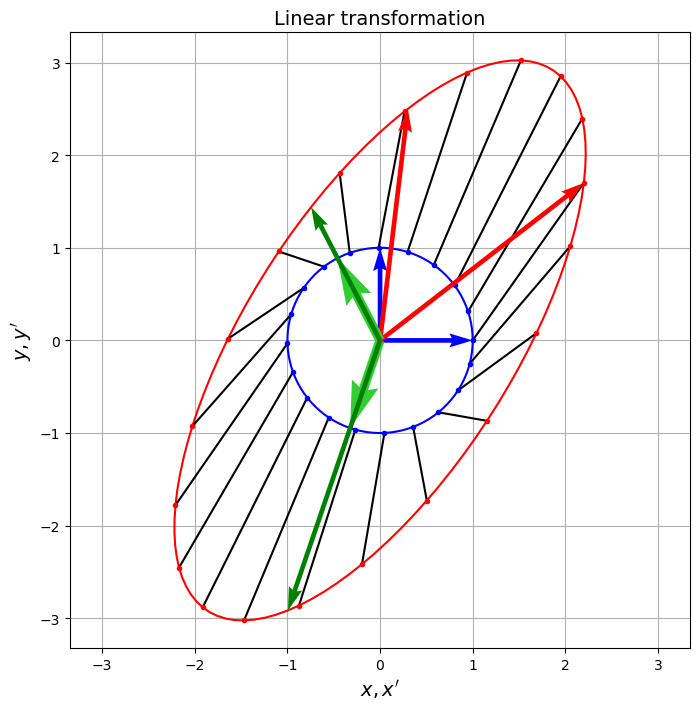

In [8]:
fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(111)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,100) # runs from 0 to 2*pi, so the curve closes

# A 2xn array of points
points = np.vstack( (np.cos(theta), np.sin(theta)) )

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation', fontsize=14)
ax1.grid(True)

x = np.array([1,0])
y = np.array([0,1])

# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue')

# plot some vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)


# choose a random transformation matrix
A = np.array([[2.2,0.3],[1.7,2.5]])

xp = A@x
yp = A@y
pointsp = A@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], color='red')

# plot the transformed vectors
ax1.quiver(xp[0], xp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)
ax1.quiver(yp[0], yp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)

# plot a subset of vectors and how they transform
for i, angle in enumerate(theta[::5]):  # don't use all the angles
    #ax1.plot([0,points[0,5*i]],[0,points[1,5*i]],'k')
    ax1.plot([points[0,5*i],pointsp[0,5*i]],[points[1,5*i],pointsp[1,5*i]],'k')
    ax1.plot([points[0,5*i]],[points[1,5*i]],'b.')
    ax1.plot([pointsp[0,5*i]],[pointsp[1,5*i]],'r.')

# compute and plot some special directions!
lam, vecs = sl.eig(A)

# plot the unit eigenvectors
ax1.quiver(vecs[0,0], vecs[1,0], angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)
ax1.quiver(vecs[0,1], vecs[1,1], angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)

# plot the scaled eigenvectors
ax1.quiver(np.real(lam[0])*vecs[0,0], np.real(lam[0])*vecs[1,0], angles='xy', scale_units='xy', 
           scale=1, color='g', zorder=30)
ax1.quiver(np.real(lam[1])*vecs[0,1], np.real(lam[1])*vecs[1,1], angles='xy', scale_units='xy', 
           scale=1, color='g', zorder=30)

ax1.axis('equal')

The blue arrows are the original basis vectors, the red are what they transform to (the columns of $A$ here) - we've seen this sort of thing already. 


The blue dots show a subset of the points (at a finite resolution - `theta[::5]` in the code above "prunes" the number of points), showing how unit vectors or points on the initial unit circle (in blue) map to new locations indicated by the red dots with black lines in between clarifying the correspondence.

Note how  the new locations/vectors now map out a (non-unit) ellipse (some stretching and rotation has gone on).

I have also added some *special* vectors/directions here - notice that the green arrows do not change their orientation, only their magnitude!

These are special directions we will talk about shortly.

But first ...

## A symmetric positive definite case

Let's try a case where the matrix is so-called *symmetric-positive-definite* (which is defined in the lecture notes, section on SPD matrices).

(-4.333364, 4.332092, -3.935385, 3.933983)

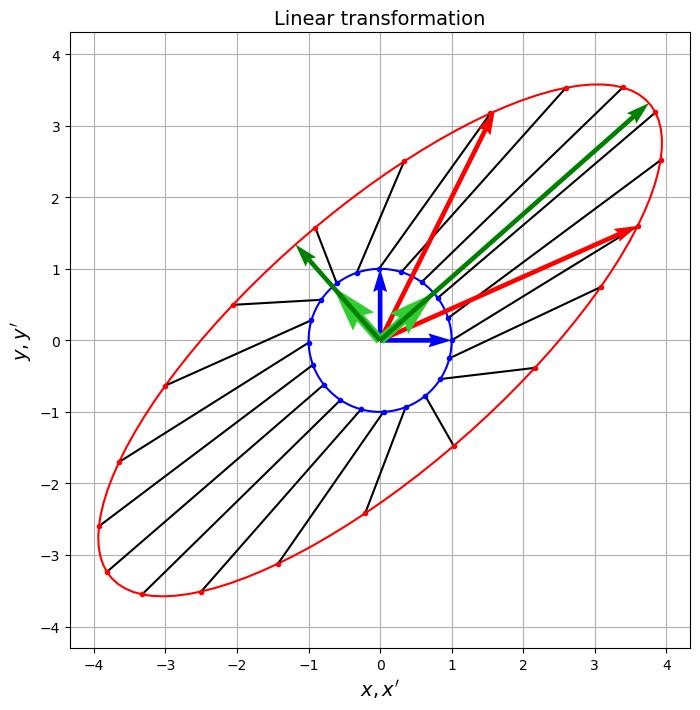

In [9]:
fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(111)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,100) # runs from 0 to 2*pi, so the curve closes

# A 2xn array of points
points = np.vstack( (np.cos(theta), np.sin(theta)) )

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation', fontsize=14)
ax1.grid(True)

x = np.array([1,0])
y = np.array([0,1])


# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue')

# plot some vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)

# an SPD example matrix
A = 2*np.array([[1.8,0.8],[0.8,1.6]])

xp = A@x
yp = A@y
pointsp = A@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], color='red')

# plot the transformed vectors
ax1.quiver(xp[0], xp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)
ax1.quiver(yp[0], yp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)

# plot a subset of vectors and how they transform
for i, angle in enumerate(theta[::5]):  # don't use all the angles
    #ax1.plot([0,points[0,5*i]],[0,points[1,5*i]],'k')
    ax1.plot([points[0,5*i],pointsp[0,5*i]],[points[1,5*i],pointsp[1,5*i]],'k')
    ax1.plot([points[0,5*i]],[points[1,5*i]],'b.')
    ax1.plot([pointsp[0,5*i]],[pointsp[1,5*i]],'r.')

# compute and plot some special directions!
lam, vecs = sl.eig(A)

# plot the unit eigenvectors
ax1.quiver(vecs[0,0], vecs[1,0], angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)
ax1.quiver(vecs[0,1], vecs[1,1], angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)

# plot the scaled eigenvectors
ax1.quiver(np.real(lam[0])*vecs[0,0], np.real(lam[0])*vecs[1,0], angles='xy', scale_units='xy', 
           scale=1, color='g', zorder=30)
ax1.quiver(np.real(lam[1])*vecs[0,1], np.real(lam[1])*vecs[1,1], angles='xy', scale_units='xy', 
           scale=1, color='g', zorder=30)

ax1.axis('equal')

In this case notice that the *special* directions correspond with the [semi-major and semi-minor axes](https://en.wikipedia.org/wiki/Semi-major_and_semi-minor_axes) of the ellipse.



# Some applications of eigen-values/vectors

   
## Linear systems 

Let's consider a linear system we solved in the previous lecture.

$$ A\boldsymbol{x}=\boldsymbol{b} \iff \sum_{j=1}^n a_{ij} x_j = b_i \quad\text{for}\quad i=1,\ldots, n $$

We noted that we can interpret the matrix vector multiplication as computing a weighted sum of the columns of the matrix (denoted by $\boldsymbol{a}_{\,:j}$):

$$
\begin{pmatrix}
      &     &         &     \\
      &     &         &     \\
  \boldsymbol{a}_{\,:1} & \boldsymbol{a}_{\,:2} &  \ldots & \boldsymbol{a}_{\,:n} \\
      &     &         &     \\
      &     &         &     \\
\end{pmatrix}
\begin{pmatrix}
    x_1\\
    x_2\\
    \vdots\\
    x_n
\end{pmatrix}
=
x_1 
\begin{pmatrix}
       \\
       \\
   \boldsymbol{a}_{\,:1} \\
       \\
    ~   
\end{pmatrix}
+
x_2 
\begin{pmatrix}
       \\
       \\
   \boldsymbol{a}_{\,:2} \\
       \\
    ~   
\end{pmatrix}
+ \cdots +
x_n
\begin{pmatrix}
       \\
       \\
   \boldsymbol{a}_{\,:n} \\
       \\
    ~   
\end{pmatrix}
$$

and solving the linear system can be interpreted as asking the question, given directions in an $n$-dimensional space prescribed by the column vectors of the matrix, how far do we need to move in each of these directions to reach the point $\boldsymbol{b}$.  

If the columns are linearly independent then we can reach any point, equivalently we can find a unique solution and the matrix is invertible. 

[As we saw in the previous lecture, if the columns aren't linearly independent, then we may be able to find a (non-unique) solution if $\boldsymbol{b}$ is located in the range of the columns of $A$.]

We explained this graphically with the following image/example.


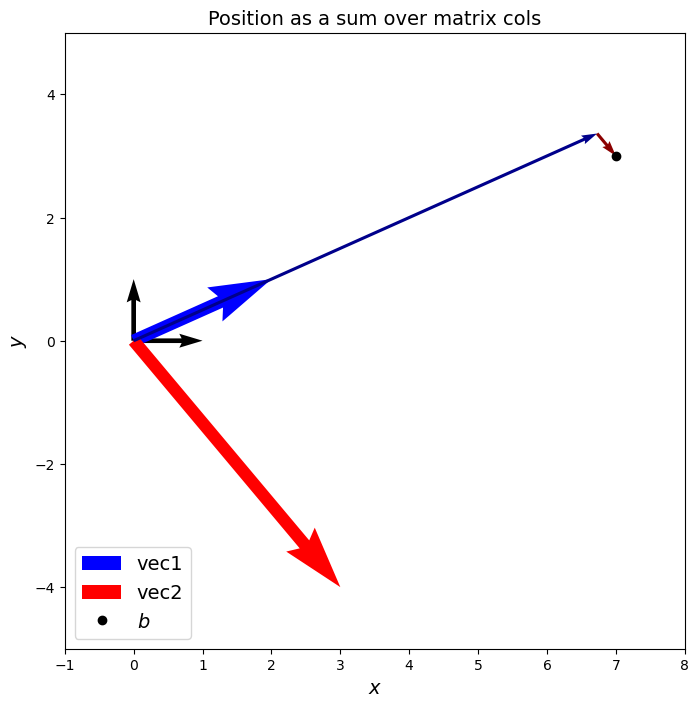

In [10]:
fig = plt.figure(figsize=(8, 8))

ax1 = fig.add_subplot(111)

ax1.set_xlabel("$x$", fontsize=14)
ax1.set_ylabel("$y$", fontsize=14)
ax1.set_title('Position as a sum over matrix cols', fontsize=14)
#ax1.grid(True)

x = np.array([1,0])
y = np.array([0,1])

# plot the vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='k')
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='k')


ax1.set_xlim(-1,8)
ax1.set_ylim(-5,5)

A = np.array([[2, 3], [1, -4]])
vec1 = A[:,0] # NB. This is the same as A@x
vec2 = A[:,1] # NB. This is the same as A@y

# plot them
ax1.quiver(vec1[0], vec1[1], angles='xy', scale_units='xy', scale=1, color='b', width=0.02,  label='vec1')
ax1.quiver(vec2[0], vec2[1], angles='xy', scale_units='xy', scale=1, color='r', width=0.02,  label='vec2')

# add point b
b = np.array([7., 3.])
ax1.plot(b[0], b[1], 'ko',  label='${b}$')

ax1.legend(loc='lower left', fontsize=14)

# Now move x_1 in the direction given by column one, followed by x_2 in the direction given by column 2:
x = np.array([37./11, 1./11])
ax1.quiver(x[0]*vec1[0], x[0]*vec1[1], angles='xy', scale_units='xy', scale=1, color='darkblue', width=0.005,  label='vec1')
ax1.quiver(x[0]*vec1[0], x[0]*vec1[1],x[1]*vec2[0], x[1]*vec2[1], angles='xy', 
           scale_units='xy', scale=1, color='darkred', width=0.005,  label='vec2')

### Re-interpretation in terms of eigenvalues and eigenvectors

Let's reconsider this problem in light of what we now know about matrix diagonalisation.

Assume we can diagonalise our matrix as $A=P\Lambda P^{-1}$,

well firstly note of course we can solve our problem trivially:

\begin{align*}
A\boldsymbol{x} &= \boldsymbol{b} \\
\iff P\Lambda P^{-1}\boldsymbol{x} &= \boldsymbol{b} \\
\iff \Lambda P^{-1} \boldsymbol{x} &=  P^{-1}\boldsymbol{b} \\
\iff  P^{-1} \boldsymbol{x} &= \Lambda^{-1} P^{-1}\boldsymbol{b} \\
\iff   \boldsymbol{x} &= P \Lambda^{-1} P^{-1}\boldsymbol{b}
\end{align*}

but actually let's not do this and think about things geometrically:

If we define $\boldsymbol{y}=P^{-1}\boldsymbol{x}\iff \boldsymbol{x}=P\boldsymbol{y}$ we can write

\begin{align*}
A\boldsymbol{x} &= \boldsymbol{b} \\
\iff P\Lambda P^{-1}\boldsymbol{x} &= \boldsymbol{b} \\
\iff P\Lambda  \boldsymbol{y} &= \boldsymbol{b}
\end{align*}

This is a different linear system, the RHS is unchanged (we still need to reach the same location), but the LHS matrix is different, note that it is

$$P\Lambda = \left[ \; \boldsymbol{v_1} \;\;  \boldsymbol{v_2}  \; \; \cdots \; \;  \boldsymbol{v_n} \; \right] 
\begin{pmatrix}
\lambda_1 & 0 &  \cdots & 0 \\
0 & \lambda_2 &  \ddots & 0\\
\vdots & &  \ddots  & \vdots \\
0 & \cdots & 0 & \lambda_n
\end{pmatrix}
= \left[ \; \lambda_1 \boldsymbol{v_1} \;\;  \lambda_2\boldsymbol{v_2}  \; \; \cdots \; \; \lambda_{n} \boldsymbol{v_n} \; \right]$$

So in solving for $\boldsymbol{y}$ we are asking the question how far do we need to move in the directions given by the  eigenvectors (scaled by the corresponding eigenvalues) to reach location $\boldsymbol{b}$?  

Once we've achieved this we can recover the solution we want by multiplying by $P$: $\boldsymbol{x}=P\boldsymbol{y}$.

Let's check this via the example above:
    

x = Py: True


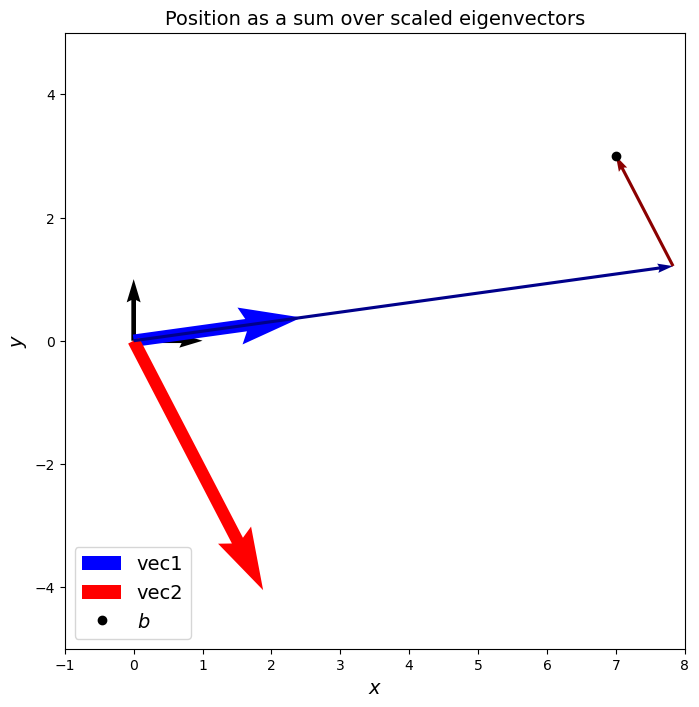

In [11]:
fig = plt.figure(figsize=(8, 8))

ax1 = fig.add_subplot(111)

ax1.set_xlabel("$x$", fontsize=14)
ax1.set_ylabel("$y$", fontsize=14)
ax1.set_title('Position as a sum over scaled eigenvectors', fontsize=14)
#ax1.grid(True)

i = np.array([1,0])
j = np.array([0,1])

# plot the vectors
ax1.quiver(i[0], i[1], angles='xy', scale_units='xy', scale=1, color='k')
ax1.quiver(j[0], j[1], angles='xy', scale_units='xy', scale=1, color='k')

ax1.set_xlim(-1,8)
ax1.set_ylim(-5,5)

A = np.array([[2, 3], [1, -4]])

# compute the e'vals/vecs
lam, vecs = sl.eig(A)
# scaled directions
vec1 = np.real(lam)[0]*vecs[:,0] 
vec2 = np.real(lam)[1]*vecs[:,1] 

# plot them
ax1.quiver(vec1[0], vec1[1], angles='xy', scale_units='xy', scale=1, color='b', width=0.02,  label='vec1')
ax1.quiver(vec2[0], vec2[1], angles='xy', scale_units='xy', scale=1, color='r', width=0.02,  label='vec2')

# add point b
b = np.array([7., 3.])
ax1.plot(b[0], b[1], 'ko',  label='${b}$')

ax1.legend(loc='lower left', fontsize=14)

# Solve the transformed problem for y
y = sl.inv(vecs@np.diag(np.real(lam)))@b
ax1.quiver(y[0]*vec1[0], y[0]*vec1[1], angles='xy', scale_units='xy', scale=1, color='darkblue', width=0.005,  label='vec1')
ax1.quiver(y[0]*vec1[0], y[0]*vec1[1], y[1]*vec2[0], y[1]*vec2[1], angles='xy', 
           scale_units='xy', scale=1, color='darkred', width=0.005,  label='vec2')

# and confirm that x (=sl.inv(A)@b) = Py
print('x = Py:',np.allclose(sl.inv(A)@b, vecs@y))

    
The red and blue arrows this time are the eigenvectors scaled by the eigenvalues.

Note that this emphasises that if $\boldsymbol{b}$ is in the direction of an eigenvector (or a sum of some of the eigenvectors), then the solution $\boldsymbol{y}$ will be especially simple.

Now finding the eigenvalues and eigenvectors is very difficult for large matrices, and so that above isn't actually useful in practice for solving linear systems.

However, note that the idea of solving a related linear system following a transformation, where ideally the transformed problem is easier to solve in some sense, is related to the topic of matrix [preconditioning](https://en.wikipedia.org/wiki/Preconditioner).
    



## Powers of matrices [\* - but note we are going to use this result in the next section]

An immediate application of the ability to diagonalise matrices is the following.

Consider 

$$A = 
\begin{pmatrix}
1.01 & 0.01 \\
0.01 & 1.01
\end{pmatrix}$$

Let's suppose our task is to raise this matrix to the power of ten thousand, i.e. to calculate

$$A^{10000} = A \,A \,\cdots \,A$$

where each of the 10000 individual multiplications is the normal matrix-matrix multiplication. 

First let's do this by brute force and compare against NumPy.


In [12]:
A = np.array([[1.01, 0.01], [0.01,1.01]])

# work out the square using matrix multiplication
print(A@A)
# check this gives the same answer as matrix_power
print('\n',np.linalg.matrix_power(A,2))

# write our own function
def our_matrix_power(A,n):
    mat_power = np.eye(np.shape(A)[0])
    for i in range(n):
        mat_power = A@mat_power   # (in-place mat_power @= A also works in NumPy >= 1.25)
    return mat_power

print('\n',our_matrix_power(A,10000))

print('\nOur method agrees with numpy on what A^{10000} equals: ', 
      np.allclose(our_matrix_power(A,10000), np.linalg.matrix_power(A,10000)),'\n')

time_np = %timeit -n 10 -r 3 -o AA = np.linalg.matrix_power(A,10000)
time_us = %timeit -n 10 -r 3 -o AA = our_matrix_power(A,10000)

print('\n',time_np.best, time_us.best, time_us.best/time_np.best)

[[1.0202 0.0202]
 [0.0202 1.0202]]

 [[1.0202 0.0202]
 [0.0202 1.0202]]

 [[5.019814e+85 5.019814e+85]
 [5.019814e+85 5.019814e+85]]

Our method agrees with numpy on what A^{10000} equals:  True 

14.6 μs ± 1.47 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)
6.05 ms ± 71.1 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)

 1.3519998174160718e-05 0.005952080001588911 440.24266312139486



Some comments/observations:

1. Why did I choose this matrix (with entries close to one and zero), and limit myself to a power of 10000?


2. Our naive approach is comparatively very slow, let's try using the fact that we know how to diagonalise a matrix


\begin{align*}
A &= P\Lambda P^{-1} \\
\implies A^2 & = P\Lambda P^{-1} P\Lambda P^{-1}  = P\Lambda \Lambda P^{-1} = P\Lambda^2 P^{-1} \\
& \; \vdots \\
\implies A^N & = P\Lambda P^{-1} P\Lambda^{N-1} P^{-1}= P\Lambda \Lambda^{N-1} P^{-1} = P\Lambda^N P^{-1}
\end{align*}

So to compute the $N$-th power of the original matrix we can diagonalise, raise the diagonal matrix of eigenvalues only to the power of $N$, and then reconstruct the matrix by pre- and post-multiplying by the matrix of eigenvectors and its inverse.

Efficiency savings should result since

$$\Lambda^N = 
\begin{pmatrix}
\lambda_1^N & 0 &  \cdots & 0 \\
0 & \lambda_2^N &  \ddots & 0\\
\vdots & &  \ddots & \vdots \\
0 & \cdots &  0 & \lambda_n^N
\end{pmatrix}$$

can be computed element-wise.

Let's write a new function to do this, and see if this helps with performance.
    

In [13]:
A = np.array([[1.01, 0.01], [0.01,1.01]])

def our_matrix_power2(A,n):
    mat_power = np.eye(np.shape(A)[0])
    lam, vecs = sl.eig(A)
    re_lam = np.real(lam)  # make the assumption that all e'vals are real
    re_lam_power = re_lam**n  # operate on individual entries of the vector of e'vals 
    return vecs@np.diag(re_lam_power)@sl.inv(vecs)

print('Our two methods agree what A^{10000} equals: ', 
      np.allclose(our_matrix_power(A,10000), our_matrix_power2(A,10000)),'\n')

time_np = %timeit -n 10 -r 3 -o AA = np.linalg.matrix_power(A,10000)
time_us = %timeit -n 10 -r 3 -o AA = our_matrix_power(A,10000)
time_us2 = %timeit -n 10 -r 3 -o AA = our_matrix_power2(A,10000)

print('\n',time_np.best, time_us.best, time_us2.best)

Our two methods agree what A^{10000} equals:  True 

14.6 μs ± 903 ns per loop (mean ± std. dev. of 3 runs, 10 loops each)
6.12 ms ± 228 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)
24.2 μs ± 9.5 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)

 1.3639999087899923e-05 0.005887500010430813 1.724000321701169e-05


In [14]:
# let's try a larger problem where NumPy might not perform so well

N = 1000
A = np.eye(N) + 0.0001*np.random.random((N,N))
A = (A+A.T)/2.

n = 1000
print('Our 2nd method agrees with numpy on what A^{n} equals: ', 
      np.allclose(our_matrix_power2(A,n), np.linalg.matrix_power(A,n)),'\n')

time_np = %timeit -o AA = np.linalg.matrix_power(A,n)
#time_us = %timeit -n 10 -r 3 -o AA = our_matrix_power(A,n)
time_us2 = %timeit -o AA = our_matrix_power2(A,n)

print(time_np.best, time_us2.best, time_us2.best/time_np.best)

Our 2nd method agrees with numpy on what A^{n} equals:  True 

51.5 ms ± 1.14 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
345 ms ± 7.14 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
0.04932245999807492 0.33768070000223815 6.846388035297063



    
So the diagonalisation approach brings us within a small factor of NumPy's `matrix_power` (on the machine used to run these notes, about 1.2 times slower for the $2\times 2$ case and about 5 times slower for this $1000\times 1000$ matrix - the exact numbers depend on your machine). Both versions hand the heavy lifting to compiled code (`np.linalg.matrix_power` uses repeated squaring, i.e. only about $2\log_2 n$ matrix products, while ours needs one eigendecomposition plus two products): <https://en.wikipedia.org/wiki/Basic_Linear_Algebra_Subprograms> and <https://en.wikipedia.org/wiki/LAPACK>, or <https://en.wikipedia.org/wiki/Math_Kernel_Library> on Windows.
    


### Fibonacci numbers 

In the homework you're asked to find the eigenvalues and eigenvectors of the so-called Fibonacci matrix.

With this knowledge we can efficiently compute (in principle) any Fibonacci number.

We'll delay doing this until the next lecture as it offers a good learning experience for some of the ways that algorithms can go wrong!
    

## Using linear algebra to solve systems of ODEs

### The idea/theory

Suppose we want to solve the linear problem that can be written in the form

$$\dot{\boldsymbol{x}}(t) = \frac{\boldsymbol{dx}}{dt} = \boldsymbol{x}' = A\boldsymbol{x}$$

Consistent with the scalar case, the solution to this problem is simply

$$\boldsymbol{x}(t) = \exp(tA) \boldsymbol{C}$$

where $\boldsymbol{C}$ is a constant (vector) of integration.

We can see that this is true if we know how the [matrix exponential](https://en.wikipedia.org/wiki/Matrix_exponential#Linear_differential_equation_systems) is defined:

$$\exp(tA) = I + tA + \frac{t^2}{2!}A^2 + \frac{t^3}{3!}A^3 + \cdots$$

and then note that differentiation of this w.r.t. $t$ is simply

$$\frac{d}{dt}\exp(tA) = A + tA^2 + \frac{t^2}{2!}A^3 + \cdots$$

and so indeed 

$$\frac{d}{dt}\exp(tA) = A(I + tA + \frac{t^2}{2!}A^2 + \frac{t^3}{3!}A^3 + \cdots) = A\exp(tA),$$

so $\dot{\boldsymbol{x}}(t) = A\exp(tA)\boldsymbol{C} = A\boldsymbol{x}(t)$.


<br>
<br>

Just as above, we can compute $\exp(tA)$ in a particularly simple/efficient form if we can diagonalise it, since then as 

$$A^n = P\Lambda^n P^{-1}$$

we can see that

\begin{align*}
\exp(tA) &= 
I + t  P
\begin{pmatrix}
\lambda_1 & 0 &  \cdots & 0 \\
0 & \lambda_2 &  \ddots & 0\\
\vdots &  & \ddots  & \vdots \\
0 & \cdots &  0 & \lambda_n
\end{pmatrix}
 P^{-1}\\[5pt] 
 &\qquad \qquad
+ \frac{t^2}{2!}  P
\begin{pmatrix}
\lambda_1^2 & 0 &  \cdots & 0 \\
0 & \lambda_2^2  & \ddots & 0\\
\vdots & &  \ddots  & \vdots \\
0 & \cdots &  0 & \lambda_n^2
\end{pmatrix}
 P^{-1} + \cdots\\[15pt]
 & = 
 P\begin{pmatrix}
e^{\lambda_1 t} & 0 &  \cdots & 0 \\
0 & e^{\lambda_2 t} &  \ddots & 0\\
\vdots & &  \ddots &  \vdots \\
0 & \cdots &  0 & e^{\lambda_n t}
\end{pmatrix}
 P^{-1}
\end{align*}

so we don't actually need to compute all of those individual matrix-matrix multiplications to form the exponential.

Now since $\exp(tA) = I$ when $t=0$, this tells us that the constant is just the initial condition: $\boldsymbol{C} = \boldsymbol{x}(t=0)$.


   
### An example

Let's consider a $2\times 2$ example where

$$\boldsymbol{x}(t) = 
\begin{pmatrix}
x_1(t)\\
x_2(t)
\end{pmatrix}$$

and 

$$A = 
\begin{pmatrix}
-1 & 3 \\
3 & -1
\end{pmatrix}
$$

A homework exercise asks you to apply the theory above to show that the solution is

\begin{align*}
\boldsymbol{x}(t) =  \exp(tA) \boldsymbol{C}
= \frac{1}{2}(C_1+C_2)
\begin{pmatrix}
1 \\
1
\end{pmatrix}\exp(2t)+
\frac{1}{2}(C_2-C_1)
\begin{pmatrix}
-1 \\
1
\end{pmatrix}\exp(-4t)
\end{align*}

and check that it agrees with a numerical calculation using forward Euler time-stepping - cf. the discussion to follow for the next problem on *stability*.

Our initial conditions can then be used to figure out what values the two constants of integration take - what choice of constants will lead to a solution that does *not* diverge to infinity?
    

### Making use of matrix diagonalisation

Instead of immediately writing down the solution to the problem

$$\dot{\boldsymbol{x}}(t) = A\boldsymbol{x}$$

as

$$x(t) = \exp(tA) \boldsymbol{C}$$

let's try a different approach (which also makes use of the matrix diagonalisation that allowed us to compute the matrix exponential easily).

One of the reasons that this problem might be difficult to analyse/solve is that for a non-diagonal matrix $A$ the ODEs that are encoded by this system are *coupled*. This means we cannot consider them individually in isolation, and so cannot use what we know about scalar systems.

However there is a trick we can play for a linear system:

Let's introduce a new variable $\boldsymbol{z}\,$ which is related to $\boldsymbol{x}\,$ through a linear transformation: $\boldsymbol{x} = S \boldsymbol{z}$, where $S$ is a $2 \times 2$ transformation matrix.

Substituting this into our coupled ODE system yields

\begin{align*}
\frac{d\boldsymbol{x}}{dt} & = A \boldsymbol{x}\\[5pt]
\iff \frac{d (S \boldsymbol{z})}{dt} & = AS\, \boldsymbol{z}\\[5pt]
\iff S\frac{d \boldsymbol{z}}{dt} & = AS\, \boldsymbol{z}\\[5pt]
\iff \frac{d  \boldsymbol{z}}{dt} & = S^{-1}AS\, \boldsymbol{z}.
\end{align*}

Now we **want** the transformed system to be decoupled, which is equivalent to requiring that the RHS matrix multiplier $S^{-1}AS$ is actually a diagonal matrix. 

Of course we know that assuming $A$ is actually diagonalisable, then $S=P$ - the matrix of eigenvectors, and

$$S^{-1}\,A\,S = \Lambda
\;\;(\text{and so} \;\; A = S\, \Lambda\,  S^{-1})
\;\;\;\;\;\;\textrm{where}\;\;\;\;\;\;
\Lambda = \begin{bmatrix}
\lambda_1 & 0\\
0 & \lambda_2
\end{bmatrix}.$$

<br>

In this (eigen-)basis our coupled ODE system decouples into two independent first-order ODEs:

$$\frac{dz_1}{dt} = \lambda_1 z_1, \;\;\;\;\;\;\;  \frac{dz_2}{dt} = \lambda_2 z_2.$$

For our problem from the homework exercise we know that 

$$\lambda_1 = 2\quad\text{and}\quad \lambda_2 = -4
\quad\text{so}\quad
\Lambda = \begin{pmatrix}
2 & 0 \\
0 & -4
\end{pmatrix}
$$

and

$$\boldsymbol{v}_1 =   \left(
  \begin{array}{r}
    {1} \\
    {1} 
  \end{array}
\right), \qquad 
\boldsymbol{v}_2 =   \left(
  \begin{array}{r}
    {-1} \\
    {1} 
  \end{array}
\right), \qquad
S = P = 
\begin{pmatrix}
1 & -1 \\
1 & 1
\end{pmatrix}
$$

we can solve the two uncoupled ODEs easily:

$$z_1(t) = z_1(0)\exp(2t), \qquad z_2(t) = z_2(0)\exp(-4t)$$

and then convert back to our original coordinates:

\begin{align*}
\boldsymbol{x}(t) = S\boldsymbol{z}(t) & = 
\begin{pmatrix}
1 & -1 \\
1 & 1
\end{pmatrix}
\begin{pmatrix}
z_1(0)\exp(2t) \\
z_2(0)\exp(-4t)
\end{pmatrix} \\[5pt]
& = z_1(0)\begin{pmatrix}
1  \\
1 
\end{pmatrix}
\exp(2t) +
z_2(0)\begin{pmatrix}
-1  \\
1 
\end{pmatrix}
\exp(-4t)
\end{align*}

i.e. the same solution as before just with the constants of integration in different notation.

This emphasises what we might have guessed from the form of the solution we derived first - the solution can be written as a sum of simple solutions in each of the individual directions described by the eigenvectors.



# Analysing and solving a second-order ODE (the Mass-Spring-Damper problem) 

Let's consider a higher-order ODE problem with some interesting solution behaviour which can be recast using linear algebra into a coupled system of first-order ODEs. It can then be analysed/solved using linear algebra techniques.

The mass-spring-damper system looks something like this:

*(Figure source: https://upload.wikimedia.org/wikipedia/commons/thumb/4/45/Mass_spring_damper.svg/1280px-Mass_spring_damper.svg.png)*
<img src="figures/Mass_spring_damper.svg.png" width=500px>


where $x$ is a displacement, $k$ is the stiffness of the spring and $c$ is a damping coefficient. Note that in the simplest case considered here we do not consider external forces, i.e. in particular we are ignoring gravity.

For some more details see: <https://en.wikipedia.org/wiki/Harmonic_oscillator#Damped_harmonic_oscillator>

For video describing the physics and showing experimental set-ups see <https://www.youtube.com/watch?v=ZqedDWEAUN4> and <https://www.youtube.com/watch?v=sP1DzhT8Vzo>

The displacement $x\equiv x(t)$ can be described by the following second-order ODE:

$$ma = F: \quad m\ddot{x} = -c\dot{x} -kx \iff m\ddot{x} + c\dot{x} +kx=0 \iff \ddot{x} + \frac{c}{m}\dot{x} + \frac{k}{m}x=0 $$

Note that without any damping ($c=0$) the system reverts to [simple harmonic motion](https://en.wikipedia.org/wiki/Simple_harmonic_motion) (SHM) which has a general solution which can be written in terms of sines and cosines.  Any solution we derive should recover this solution when $c=0$.





It is common to define some new parameters that allows us to write our problem in the form

$$\ddot{x} + 2\zeta\omega_0\dot{x}+\omega_0^2x=0,$$

where $\zeta= \frac{c}{\sqrt{4mk}}$ is a "damping ratio" and $\omega_0=\sqrt{\frac{k}{m}}$ is termed the "eigenfrequency" in the absence of damping.


In order to use simple time-stepping methods (or ODE solvers) which are implemented for first-order ODEs (i.e. only contain first derivatives), a standard approach is to convert this second-order ODE into two coupled first-order ODEs. In doing this it is easier for us to analyse the system and to try to find analytical solutions (as we will see we revert to a linear system like the one we saw in the previous section). 

To do this we introduce the new dependent variable 

$$v=\frac{dx}{dt}=\dot{x},$$ 

which results in the coupled first-order system:

\begin{align*}
\dot{v} & = -2\zeta\omega_0v-\omega_0^2x,\\[5pt]
\dot{x} & = v.
\end{align*}





## Writing as a linear system

The MSD system can be written in compact vector form as

$$\frac{d\boldsymbol{y}}{dt} = \boldsymbol{f}\,(t,\boldsymbol{y}),$$

where

$$\boldsymbol{y} := 
\begin{bmatrix}
x \\
v
\end{bmatrix},$$

and

$$\boldsymbol{f}\,(t,\boldsymbol{y}) := 
\begin{bmatrix}
v \\
-2\zeta\omega_0v-\omega_0^2x
\end{bmatrix}.$$

Note that as this is a linear system we can write the RHS as a matrix system:

$$\boldsymbol{f}\,(t,{\bf y}) = A \boldsymbol{y},\;\;\;\textrm{where}\;\;\;
A=
\begin{bmatrix}
0 & 1\\
-\omega_0^2 & -2\zeta\omega_0
\end{bmatrix}.$$


## Discretisation with forward Euler


Discretisation with the forward Euler method we derived and implemented in L1 leads us to the discrete form

$$\frac{\boldsymbol{y}_{n+1}-\boldsymbol{y}_{n}}{\Delta t} = \boldsymbol{f}\,(t_{n},\boldsymbol{y}_{n}) = A \boldsymbol{y}_{n},$$

or rearranging

$$\boldsymbol{y}_{n+1} = (I+A\Delta t)\boldsymbol{y}_{n}, $$

where $I$ is the $2\times 2$ identity matrix.  

Note that each time step of the solver requires us to perform the matrix-vector multiplication on the RHS.
    



**Question:**

- What does the final expression above tell us about how we can link the solution at any time level, with the initial condition $({\bf y}_0)$?


Let's compute the solution for the two components using forward Euler, and plot them, and also include the exact solution for the $x$ variable which we will compute below.
    

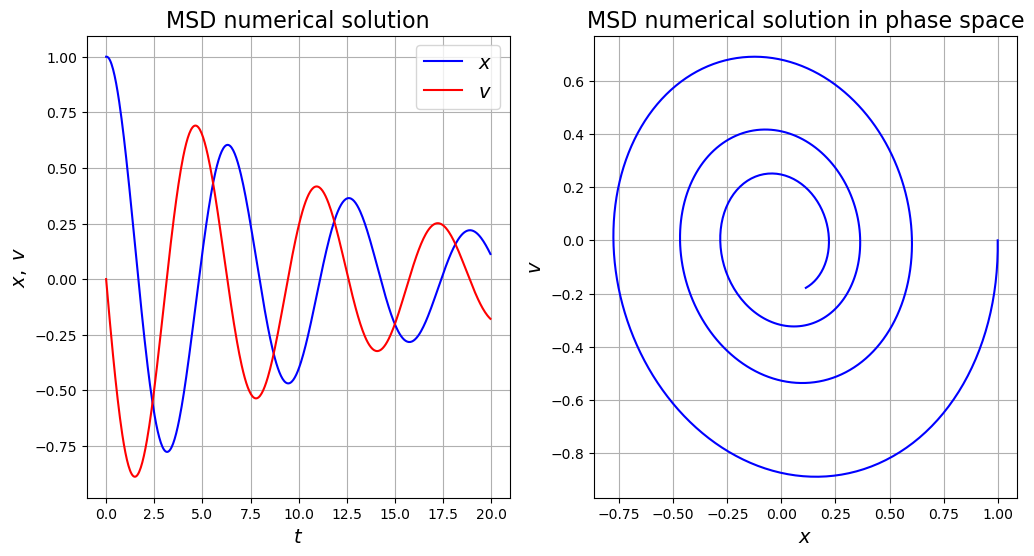

In [15]:
# numerical parameters for problem
om0 = 1
zeta = 0.1
# initial data (we need two for this coupled problem)
x0 = 1
v0 = 0
# simulation period and time step size
tend = 20
dt = 0.04
# the RHS matrix which defines the problem
A = np.array([[0, 1], [-om0**2, -2*zeta*om0]])
# the 2x2 identity matrix which we also need in our rearranged time-stepping expression
I = np.identity(2)
# set up some vectors of times and to store solution
t = np.arange(0, tend, dt)
y = np.empty((len(t), 2))
# initialise solution
y[0, :] = np.array((x0, v0))
# time step
for n in range(len(t)-1):
    y[n + 1, :] = (I + A * dt) @ y[n, :]

# pull out the individual solution vectors (don't need to do this)
x = y[:, 0]
v = y[:, 1]

fig = plt.figure(figsize=(12, 6))
ax1 = plt.subplot(121)
ax1.plot(t, x, 'b', label='$x$')
ax1.plot(t, v, 'r', label='$v$')
ax1.set_xlabel(r'$t$', fontsize=14)
ax1.set_ylabel(r'$x,\; v$', fontsize=14)
ax1.set_title('MSD numerical solution', fontsize=16)
ax1.grid(True)
ax1.legend(loc='best', fontsize=14)

ax2 = plt.subplot(122)
ax2.plot(x, v, 'b')
ax2.set_xlabel('$x$', fontsize=14)
ax2.set_ylabel('$v$', fontsize=14)
ax2.set_title('MSD numerical solution in phase space', fontsize=16)
ax2.grid(True)



    
## Exercises

- Experiment again with $\Delta t$.

[you should observe that smaller $\Delta t$ gives a better result, but for larger values the result first gets worse, and then if you continue to increase $\Delta t$ the problem is complete garbage].


- Now let's change the problem a bit...

   - physically the value of $\zeta$ tells us how much damping there is in the underlying problem - what happens if we set this to zero, i.e. there's no inherent damping in the problem (and we revert back to simple harmonic motion)?     
    
   - What do you observe about the exact solution and the numerical approximation? 

   - Is the numerical approximation now *qualitatively correct*?
    





## Analysing an ODE system: diagonalisation

Returning to the MSD system, we start from the coupled (linear) ODE system in the matrix form


$$\frac{d\boldsymbol{y}}{dt} = A \boldsymbol{y},\;\;\;\;\;\textrm{where}\;\;\;\;\;
A = \begin{bmatrix}
0 & 1\\
-\omega_0^2 & -2\zeta\omega_0
\end{bmatrix}.$$

As we saw above we can make progress in analysing this problem if we first diagonalise it.

If we can do this then we will arrive at a system of **uncoupled** ODEs which will simplify our analysis significantly. 

Just as in the previous example, 
introduce a new variable $\boldsymbol{z}$ which is related to $\boldsymbol{y}$ through a linear transformation: $\boldsymbol{y} = S \boldsymbol{z}$, where $S$ is a $2 \times 2$ transformation matrix. 

If we can diagonalise $A$ then we can write our problem in terms of an (eigen-)basis such that our coupled ODE system decouples into two independent first-order ODEs:

$$\frac{dz_1}{dt} = \lambda_1 z_1, \;\;\;\;\;\;\;  \frac{dz_2}{dt} = \lambda_2 z_2.$$


If our numerical solver does a "good job" (which we are yet to define) on these problems individually, then clearly we should have a good result when we combine these solutions to get back to our original $\boldsymbol{y}\,$ variables. 

Equally if our numerical solver performs badly on the $z$ problems, then we will not have a good solution in terms of the $\boldsymbol{y}\,$ variables. 

So we really are back to asking the question whether our numerical method deals with the linear scalar problem $\, y' = \lambda y\, $ well.

The main difference when dealing with systems in this way is that even if the original problem is *real* (i.e. not complex-valued), then the eigenvalues can absolutely be complex-valued as we shall see for certain parameter choices in the MSD problem shortly. 
    


## Eigenvalue analysis

So to perform this analysis on systems we need to find and consider the eigenvalues of the matrix $A$.

A homework exercise asks you to find the eigenvalues of this problem.

You should find the eigenvalues:

$$\lambda_1 = \omega_0\left(-\zeta + \sqrt{\zeta^2-1}\right),\;\;\;\;
\lambda_2 = \omega_0\left(-\zeta - \sqrt{\zeta^2-1}\right).$$


Note that we have three cases:
1. $\zeta=0$: purely imaginary eigenvalues

2. $0<\zeta<1$: complex eigenvalues with $Re(\lambda)<0$

3. $\zeta\ge 1$: real (negative) eigenvalues

$\zeta$ here is encoding something about the physics of our problem (refer to the linked videos above and <https://en.wikipedia.org/wiki/Harmonic_oscillator#Damped_harmonic_oscillator>).

In the three cases above the system is termed: *undamped*, *under-damped* and *over-damped* (with $\zeta=1$ *critically-damped*), respectively.
    



## Stability of the *continuous problem*

It's quite important for us to have an idea whether our continuous problem has exact solution behaviour which is *stable*, in that it doesn't diverge to infinity, as in the case that this is true we will want our discretised problem to have similar behaviour. Often this behaviour (for both the continuous and discrete problems) is dependent on both physical and numerical parameters.


The above diagonalisation of our coupled problem shows that we can actually consider the generic scalar problem


$$\frac{dz}{dt}=\lambda z, \;\;\;\; z(0)=1,$$


for each of the eigenvalues (which remember may be complex valued) of the matrix $A$.


It doesn't matter what initial condition we choose here, we've just chosen the value $(1)$ that leads to the simple solution:

$$ z(t) = \exp(\lambda t).$$

The solution to this problem is termed **stable** if 

$$\lim_{t\rightarrow\infty}z(t)=0,$$

i.e. if solutions are attracted to the fixed point $z=0$. 

The alternative is termed **unstable** and here $z$ would diverge to infinity.

Here (in the continuous case) stability occurs for $Re(\lambda)<0$, and $z$ diverges for $Re(\lambda)>0$. (If $Re(\lambda)=0$ then $|z(t)|=1$ for all $t$: the solution neither decays nor grows - the undamped case $\zeta=0$ of the MSD problem.)

For a general mathematical discussion of stability/fixed point etc of differential equations see <https://en.wikipedia.org/wiki/Stability_theory>.
    


**Aside**

We can see this from [*Euler's formula*](https://en.wikipedia.org/wiki/Euler%27s_formula) which here tells us that

\begin{align*}
z(t)=\exp(\lambda t)&=\exp(\lambda_Rt)\exp(i\lambda_It)\\[5pt]
& = \exp(\lambda_Rt)\left(\cos(\lambda_It) + i\sin(\lambda_It)\right),
\end{align*}

where $\,i=\sqrt{-1}$, $\,\lambda_R=Re(\lambda)$, $\,\lambda_I=Im(\lambda)$.

The result now follows from the fact that $\sin$ and $\cos$ are bounded.

This is because the imaginary part of the above ($i\sin(\lambda_It)$) just oscillates with a magnitude less than one, so it does not impact on whether the long time behaviour of the system converges to zero or infinity, this is dictated by the $\exp(\lambda_Rt)$ factor.

Similarly the real part of the above includes the bounded oscillatory term ($\cos(\lambda_It)$) multiplied again by the 
$\exp(\lambda_Rt)$ factor which again controls whether the system converges to zero or infinity.

So it really is the behaviour of $\exp(\lambda_Rt)$ that dominates, and this behaviour is dictated by whether $\,\lambda_R=Re(\lambda)$ is positive or negative.

You could choose some complex numbers and plot this solution in the complex plane to convince yourself that the imaginary part just leads to bounded oscillations, and the real part controls the growth or decay.


    
So without actually solving the problem, the eigenvalues tell us a lot about the qualitative behaviour of the solution.


**But** if we can actually solve the problem analytically then of course this gives us both qualitative as well as quantitative information we can directly compare any numerical solution against.
     


## The exact solution

Consider the problem in second-order form

$$\ddot{x} + 2\zeta\omega_0\dot{x}+\omega_0^2x=0$$

A way to solve a homogeneous (zero RHS) linear problem of this form is to seek solutions made up of special functions (see <https://en.wikipedia.org/wiki/Linear_differential_equation#Homogeneous_equation_with_constant_coefficients>).

We search for solutions of the form

$$x(t) = \exp(\alpha t)$$

where $\alpha$ is an unknown constant. 

Note that this simple form of solution guess allows us to write down its derivatives trivially:

$$\dot{x}(t) = \alpha \exp(\alpha t) = \alpha x(t), \qquad
\ddot{x}(t) = \alpha^2 x(t)
$$

substituting into our ODE

$$\left(\alpha^2 + 2\zeta\omega_0\alpha +\omega_0^2 \right)x(t)=0
$$

since the form of $x(t)$ we are considering is non-zero, we must have that

$$\alpha^2 + 2\zeta\omega_0\alpha +\omega_0^2 =0
$$

This is a quadratic with the roots

\begin{align*}
\alpha_{\pm} &= \frac{-2\zeta\omega_0 \pm \sqrt{4\zeta^2\omega_0^2 - 4\omega_0^2}}{2}\\[5pt]
& = -\omega_0\left( \zeta \pm \sqrt{\zeta^2-1}\right)
\end{align*}

[If you're paying attention, technically it should be $\mp$ in the second line since I took a minus sign outside the bracket, but it doesn't really make any difference to how we progress.]

So 

$$x(t) = \exp(\alpha_+ t)\qquad \text{and}\qquad
x(t) = \exp(\alpha_- t)$$

are both solutions to the problem, by linearity and the fact that the problem is homogeneous we can multiply each by an arbitrary constant and we can sum them:

$$x(t) = C_1\exp(\alpha_+ t) + C_2\exp(\alpha_- t)$$

we now have two unknowns $C_1$ and $C_2$ which can be fixed based on the initial conditions.  

At this stage it's important to remember that the constants appearing here could be complex valued, and this will actually be important to ensure that the solution we end up with is real, even in the case when $\alpha_{\pm}$ are complex!

Let's plug in $t=0$:

$$x(0) = C_1+C_2$$

Now since we are considering a physical problem where displacement is given by a real number, while the constants may be complex, the imaginary part of their sum $C_1+C_2$ must vanish/cancel. This means that $\text{Im}C_1 = -\text{Im}C_2$.

If we differentiate our form of solution, and plug in $t=0$ again, we have

$$v(0)=\dot{x}(0)= C_1\alpha_+ + C_2\alpha_-$$

in the under-damped case $0<\zeta<1$ considered below, $\alpha_{\pm}$ are a complex-conjugate pair, let's write them as $\alpha_{\pm} = a \pm ib$, then 

\begin{align*}
v(0)=\dot{x}(0) &= (\text{Re}C_1 + i\text{Im}C_1)(a+ib)  + (\text{Re}C_2 + i\text{Im}C_2)(a-ib) \\[5pt]
&= a (\text{Re}C_1+\text{Re}C_2) + b(\text{Im}C_2 - \text{Im}C_1) 
+ i \left[b(\text{Re}C_1 - \text{Re}C_2) + a(\text{Im}C_1 +\text{Im}C_2)  \right]
\end{align*}

We already know that $\text{Im}C_1 = -\text{Im}C_2$, and hence for the imaginary part of the initial velocity to vanish we also need that $\text{Re}C_1 = \text{Re}C_2$. Together this means that to get a real solution (and its derivative), the constants $C_1$ and $C_2$ need to be complex conjugates of one another - we still have two unknowns we need to fix, the real and the imaginary parts of this constant.

So what have we established?

The solution is given by

$$x(t) = C_1\exp(\alpha_+ t) + C_2\exp(\alpha_- t)$$

where both the $C$'s and the $\alpha$'s are complex conjugates.

We already wrote $\alpha_{\pm} = a \pm ib$, let's also write

$$C_1 = |C|\exp(i\phi), \qquad\text{and so} \qquad C_2 = |C|\overline{\exp(i\phi)}$$ 

Our solution can now be written as

\begin{align*}
x(t) &= C_1\exp(\alpha_+ t) + C_2\exp(\alpha_- t)\\[5pt]
&=|C|\exp(at)\left( \exp(i\phi)\exp(ibt) + \overline{\exp(i\phi)}{\exp(-ibt)} \right)\\[5pt]
&=|C|\exp(at)\left( \exp(i(bt+\phi)) + {\exp(-i(bt+\phi))}\right)\\[5pt]
&=2|C|\exp(at)\cos(bt+\phi)
\end{align*}

where $a$ and $b$ come from our already computed eigenvalues (the real and imaginary components), 
and $|C|$ and $\phi$ are the unknowns we need to compute from our initial conditions.

The derivative gives us the $v$ solution:

\begin{align*}
v(t) = \dot{x}(t) &= \frac{d}{dt}2|C|\exp(at)\cos(bt+\phi)\\[5pt]
&= 2|C|\exp(at)\left(-b\sin(bt+\phi) + a \cos(bt+\phi)  \right)
\end{align*}



Consider the case $0<\zeta<1$, the eigenvalues are a complex conjugate pair given by

$$\lambda_1 = -\omega_0\zeta + \omega_0\sqrt{1-\zeta^2}i,\;\;\;\;
\lambda_2 = -\omega_0\zeta - \omega_0\sqrt{1-\zeta^2}i.$$

In this case

$$a = -\omega_0\zeta, \qquad\text{and}\qquad b = \omega_0\sqrt{1-\zeta^2}=:\omega$$

we've introduced this variable $\omega$ to stop us having to write out and compute the full expression repeatedly.

We can write the solution in this case as

$$x(t) = 2|C|\exp(-\omega_0\zeta t)\cos(\omega\,t + \phi)$$

and 

$$v(t) = 2|C|\exp(-\omega_0\zeta t)\left(-\omega\sin(\omega t+\phi) -\omega_0\zeta \cos(\omega t+\phi)\right)$$

Let's plug in the initial condition:

$$x_0 = x(0) = 2|C|\cos(\phi)$$

and the initial velocity

$$v_0 = \dot{x}(0) =2|C|\left(-\omega\sin(\phi) -\omega_0\zeta \cos(\phi)\right)$$



Plugging the first of these into the second to cancel $C$ we have

\begin{align*}
v_0  &= \frac{x_0}{\cos(\phi)}\left(-\omega\sin(\phi) -\omega_0\zeta \cos(\phi)\right)\\[5pt]
&= x_0\left( -\omega\tan(\phi) - \omega_0\zeta  \right)\\[5pt]
\implies \phi &= \tan^{-1}\left(\frac{-v_0 - \omega_0\zeta x_0}{\omega x_0}\right)
\end{align*}

and then plugging back into the first

$$|C|=\frac{x_0}{ 2\cos(\phi)}$$



## Comparing the analytical solution against a numerical solver

Let's compute a numerical solution using the forward Euler method, and check the analytical solution we've just derived agrees with it.
    

In [16]:
def msd_exact_sol(t, x0, v0, zeta, om0):
    """Exact solution to the general MSD problem 
    Return: x and v component of solution
    """
    om = om0 * np.sqrt(1-zeta**2)
    phi = np.arctan2( (-v0 - om0*zeta*x0) , (om*x0) )
    CC = x0/(2*np.cos(phi))
    a = -om0*zeta
    b = om0 * np.sqrt(1-zeta**2)
    x_exact = 2*CC*np.exp(a*t)*np.cos(b*t+phi)
    v_exact = 2*CC*np.exp(a*t)*(-b*np.sin(b*t+phi) + a*np.cos(b*t+phi))
    return x_exact, v_exact

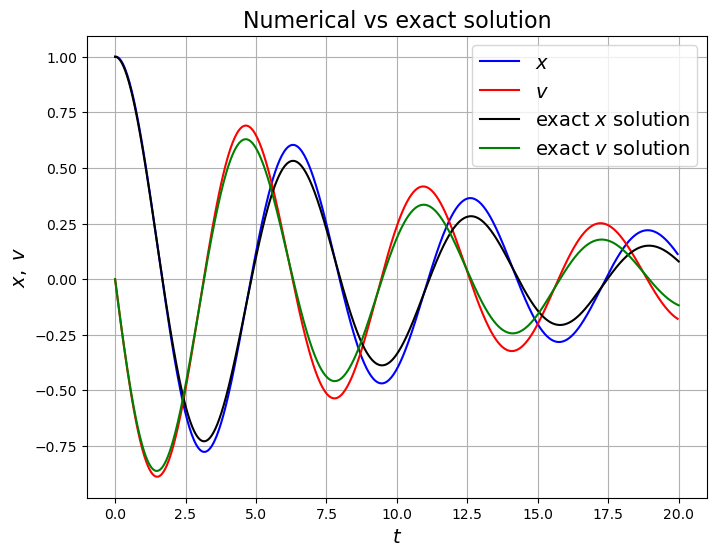

In [17]:
# numerical parameters for problem
om0 = 1
zeta = 0.1

# initial data (we need two for this coupled problem)
x0 = 1
v0 = 0
# simulation period and time step size
tend = 20
dt = 0.04
# the RHS matrix which defines the problem
A = np.array([[0, 1], [-om0**2, -2*zeta*om0]])
# the 2x2 identity matrix which we also need in our rearranged time-stepping expression
I = np.identity(2)
# set up some vectors of times and to store solution
t = np.arange(0, tend, dt)
y = np.empty((len(t), 2))
# initialise solution
y[0, :] = np.array((x0, v0))

# time step using forward Euler
for n in range(len(t)-1):
    y[n + 1, :] = (I + A * dt) @ y[n, :]

# pull out the individual solution vectors (don't need to do this)
x = y[:, 0]
v = y[:, 1]

fig = plt.figure(figsize=(8, 6))
ax1 = plt.subplot(111)
ax1.plot(t, x, 'b', label='$x$')
ax1.plot(t, v, 'r', label='$v$')
ax1.set_xlabel(r'$t$', fontsize=14)
ax1.set_ylabel(r'$x,\; v$', fontsize=14)
ax1.set_title('Numerical vs exact solution', fontsize=16)
ax1.grid(True)

tfine = np.arange(0, tend, dt/100)
x_exact, v_exact = msd_exact_sol(tfine, x0, v0, zeta, om0)
ax1.plot(tfine, x_exact, 'k', label='exact $x$ solution')
ax1.plot(tfine, v_exact, 'g', label='exact $v$ solution')
ax1.legend(loc='best', fontsize=14);

Looks good - you could check for convergence.

Let's generate an animation to check the result looks physically plausible.
    

In [18]:
import matplotlib.animation as animation
from IPython.display import HTML
    
def spring(spring_start, spring_end, y_translate):
    """Plot a 2D spring
    """
    N = 1000
    x = np.linspace(0,1,N)
    straight_bit = 100
    y = np.zeros(N)
    y[straight_bit:-straight_bit] = 0.02*np.sin(2.*np.pi*40*x[straight_bit:-straight_bit])
    ax1.plot((spring_end-spring_start)*x + spring_start, y+y_translate, 'k', lw=2)    

def damper(a, b, c, d, e, f, g):    
    """Plot a 2D damper

          ___________________                 _ f+g/2  
         |              e = piston length
    -----|          |--------------------     - f
         |___________________                 _ f-g/2

    |    |                  |           |         
    a    b                  c           d
    
    
    """
    # image made up of straight lines so the following doesn't need to be a large number
    N = 2
    xs = np.linspace(0,1,N)
    os = np.ones(N)
    # fixed bit
    ax1.plot(a + (b-a)*xs, f*os, 'k', lw=2)
    ax1.plot(b*os, f - g/2 + g*xs, 'k', lw=2)
    ax1.plot(b + (c-b)*xs, f + g/2*os, 'k', lw=2)
    ax1.plot(b + (c-b)*xs, f - g/2*os, 'k', lw=2)
    # moving bit
    ax1.plot(d-e + e*xs, f*os, 'k', lw=2)
    ax1.plot((d-e)*os, f - 0.6*(g/2 - g*xs), 'k', lw=2)
    
def background(wall, floor):    
    """Add a background
    """
    ax1.axvspan(-10, wall, color='lightgrey', zorder=5)
    ax1.axvline(x=wall, color='k', zorder=10)
    ax1.axhspan(-10, floor, color='grey', zorder=15)
    ax1.axhline(y=floor, color='k', zorder=20)
     
# set up our fig for animation     
fig = plt.figure(figsize=(9, 4))
ax1 = fig.add_subplot(111)
plt.close()

# numerical parameters for problem
om0 = 1
zeta = 0.1
# initial data (we need two for this coupled problem)
x0 = 1
v0 = 0
tfine = np.arange(0, 40, 1)
x_exact, v_exact = msd_exact_sol(tfine, x0, v0, zeta, om0)

def data_gen(framenumber, x_exact):
    ax1.clear()
    ax1.plot(x_exact[framenumber], 0.03, 'ro', ms=30, zorder=30)
    background(-3.5, 0)
    spring(-3.5, x_exact[framenumber], 0.2)
    damper(-3.5, -3, -0.9 , x_exact[framenumber], 2, 0.1, 0.04)    
    ax1.plot([x_exact[framenumber],x_exact[framenumber]], [0.03, 0.2], 'k', lw=2, zorder=25)
    ax1.set_xlim(-3.8, 1.5)
    ax1.set_ylim(-0.1, 0.3)
    ax1.set_xlabel('$x$', fontsize=14)
    ax1.set_title('MSD animation', fontsize=14)

anim = animation.FuncAnimation(fig, data_gen, frames=np.arange(0, len(x_exact)), fargs=(x_exact, ),
                               interval=50)

# save the animation as gif or mp4 if needed
#anim.save('animations/MSD.gif', writer='imagemagick')
#anim.save('animations/MSD.mp4', extra_args=['-vcodec', 'libx264'])
# display in notebook: an mp4 video needs ffmpeg installed; otherwise fall back to a
# JavaScript player (needs no external tools; reduced resolution to keep the notebook small)
if animation.writers.is_available('ffmpeg'):
    display_anim = HTML(anim.to_html5_video())
else:
    with plt.rc_context({'savefig.dpi': 50}):
        display_anim = HTML(anim.to_jshtml())
display_anim


### An aside on generating animations

Note that I am certainly not doing this optimally here, take a look here for a good discussion
<https://jakevdp.github.io/blog/2012/08/18/matplotlib-animation-tutorial/>
    


# A coupled mass spring damper system and a fancier ODE solver

Let's extend our *single* mass system

\begin{align*}
\dot{v} & = -2\zeta\omega_0v-\omega_0^2x,\\[5pt]
\dot{x} & = v.
\end{align*}

to *two* masses. 

I'm not going to compute eigenvalues etc, so let's not bother with the $\zeta$ and $\omega$ derived parameters
and stick with the original physical parameters.

The original second order equation was

$$ma = F: \quad m\ddot{x} = -c\dot{x} -kx \iff m\ddot{x} + c\dot{x} +kx=0 \iff \ddot{x} + \frac{c}{m}\dot{x} + \frac{k}{m}x=0 $$

which we saw as a coupled system of first-order equations could be written as

\begin{align*}
\dot{x} & = v\\
\dot{v} & = -\frac{c}{m}v-\frac{k}{m}x
\end{align*}

Now let's consider a system of two springs (with spring constants $k_1$ and $k_2$) with locations $x_1$ and $x_2$ and velocities $v_1$ and $v_2$. Damping is given by the terms with constants $c_1$ and $c_2$.

Assume that underscore 1 indicates the system connected to the wall, and 2 indicates a system connected to the first, which we assume is located to the right of the first. The two masses are $m_1$ and $m_2$

Then our ODE for the first is as before, but now we need to additionally account for the force due to the second spring. Also, previously we didn't need to worry about the length of the spring in its unforced state (we were implicitly assuming that this equated with $x=0$). Let's introduce $L_1$ and $L_2$ for these lengths. $x_2$ is the distance to the wall, so $x_2-x_1$ is the length of the second spring.

This can all be encapsulated in the two coupled second-order ODEs:


\begin{align*}
m_1\ddot{x}_1 &= -c_1\dot{x}_1 - k_1(x_1-L_1) + k_2(x_2 - x_1 - L_2)\\[5pt]
m_2\ddot{x}_2 &= -c_2\dot{x}_2 - k_2(x_2 - x_1 - L_2)
\end{align*}

[Note the equal but opposite forces due to the second spring].

This can be turned into a system of four first-order equations:


\begin{align*}
\dot{x}_1 &= v_1\\[5pt]
\dot{v}_1 &= \frac{1}{m_1}\left(-c_1 v_1 - k_1(x_1-L_1) + k_2(x_2 - x_1 - L_2)\right)\\[5pt]
\dot{x}_2 &= v_2\\[5pt]
\dot{v}_2 &= \frac{1}{m_2}\left(-c_2 v_2 - k_2(x_2 - x_1 - L_2)\right)
\end{align*}



We could solve this using our forward Euler solver, but let's use a much better ODE solver from SciPy.

We will review improved ODE solvers, including what is going on in the SciPy implementation in a later lecture, and for the ACSE students in your next module. If you're interested to know more now take a look at the docs <https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html>

`solve_ivp` provides a range of solvers, we will choose to use the method with the code `RK45` which for people with Matlab experience is equivalent to the default `ode45` solver.


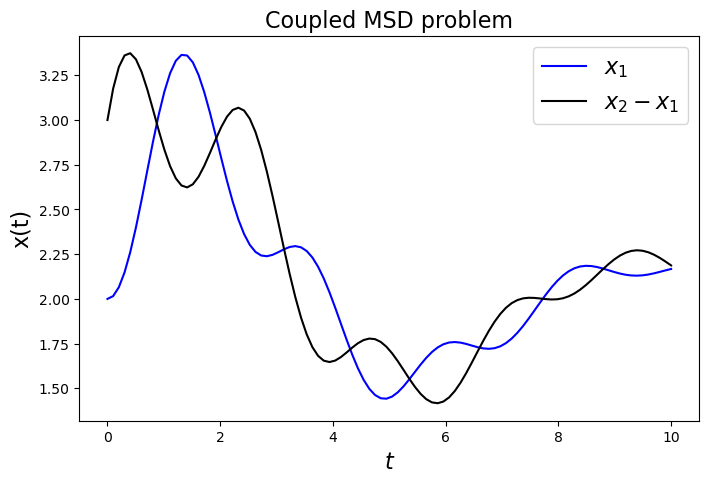

In [19]:
# let's use the solve_ivp
from scipy.integrate import solve_ivp

# we should really pass in the parameters rather than hard-coding them
def f_MSD_coupled(t, state):
    """RHS vector for the system of 1st order ODEs
    governing the coupled MSD problem in the case of two masses

    t: time
    state: state vector [x1, v1, x2, v2]
    """
    # define problems parameters:
    m1 = 1.0
    m2 = 2.5
    k1 = 4.0
    k2 = 3.0
    L1 = 2.0
    L2 = 2.0
    c1 = 0.5
    c2 = 1
    # unpack state
    x1, v1, x2, v2 = state
    # Create the RHS vector
    RHS = [v1, 
           (1/m1)*(-c1*v1 - k1*(x1 - L1) + k2*(x2 - x1 - L2)),
           v2, 
           (1/m2)*(-c2*v2 - k2*(x2 - x1 - L2))]
    return RHS


# Define initial conditions
x1 = 2
v1 = 0.
x2 = 5.
v2 = 2.

# Integration window
t0 = 0.
tf = 10.
# output time we want from the solver
ts = np.linspace(t0, tf, 100)

# A solver tolerance - not really needed here, use default
tol = 1.e-5
# call the solver
sol = solve_ivp(f_MSD_coupled, [t0, tf], np.array([x1,v1,x2,v2]), method='RK45', t_eval=ts, rtol=tol, atol=tol)

fig, ax1 = plt.subplots(1, 1, figsize=(8, 5))
ax1.plot(ts, sol.y[0,:], 'b', label='$x_1$')
ax1.plot(ts, sol.y[2,:]-sol.y[0,:], 'k', label='$x_2-x_1$')
ax1.set_xlabel('$t$', fontsize=16)
ax1.set_ylabel('x(t)', fontsize=16)
ax1.set_title('Coupled MSD problem', fontsize=16)
ax1.legend(loc='best', fontsize=16)


Recall that $x_1$ and $x_2-x_1$ are the lengths of the two springs and we specified the lengths $L_1$ and $L_2$ of the springs in an "unforced" state to be two - hence the reasons these two quantities seem to be converging to two as expected.
    

In [20]:
fig = plt.figure(figsize=(9, 4))
ax1 = fig.add_subplot(111)
   
# add a first frame
plot = ax1.plot(sol.y[0,0],0.04,'ro', ms=30)
ax1.set_xlim(-0.5, 6.5)
ax1.set_ylim(-0.1, 0.3)
plt.close()

# the dampers are a pain to plot without overlapping, so don't bother here
def data_gen(framenumber, x1, x2):
    ax1.clear()
    # first system
    ax1.plot(x1[framenumber], 0.03, 'ro', ms=30, zorder=30)
    background(0, 0)
    spring(0, x1[framenumber], 0.2)
    ax1.plot([x1[framenumber],x1[framenumber]], [0.03, 0.2], 'k', lw=2, zorder=25)
    # second system
    ax1.plot(x2[framenumber], 0.03, 'ro', ms=30, zorder=30)
    spring(x1[framenumber], x2[framenumber], 0.2)    
    ax1.plot([x2[framenumber],x2[framenumber]], [0.03, 0.2], 'k', lw=2, zorder=25)
    
    ax1.set_xlim(-0.5, 6.5)
    ax1.set_ylim(-0.1, 0.3)
    ax1.set_xlabel('$x$', fontsize=14)
    ax1.set_title('MSD animation', fontsize=14)

anim = animation.FuncAnimation(fig, data_gen, frames=np.arange(0, len(ts)), fargs=(sol.y[0,:], sol.y[2,:]),
                               interval=50)

# save the animation as gif or mp4 if needed
#anim.save('animations/MSD2.gif', writer='imagemagick')
#anim.save('animations/MSD2.mp4', extra_args=['-vcodec', 'libx264'])
# display in notebook: an mp4 video needs ffmpeg installed; otherwise fall back to a
# JavaScript player (needs no external tools; reduced resolution to keep the notebook small)
if animation.writers.is_available('ffmpeg'):
    display_anim = HTML(anim.to_html5_video())
else:
    with plt.rc_context({'savefig.dpi': 50}):
        display_anim = HTML(anim.to_jshtml())
display_anim